In [2]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition
import 

In [5]:
pip install -U langchain-huggingface sentence-transformers


  Using cached langchain_huggingface-1.2.3-py3-none-any.whl.metadata (4.3 kB)
  Using cached sentence_transformers-6.3.0-py3-none-any.whl.metadata (20 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-macosx_11_0_arm64.whl.metadata (9.8 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-macosx_11_0_arm64.whl.metadata (4.9 kB)
  Using cached torch-2.15.0-cp312-cp312-macosx_14_0_arm64.whl.metadata (36 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached safetensors-0.8.0-cp310-abi3-macosx_11_0_arm64.whl.metadata (4.2 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached symp

In [6]:
# Install: pip install langchain-huggingface sentence-transformers
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="BAAI/bge-small-en-v1.5")


/Users/sanket/Desktop/Agentic_ai/langgraph_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1121 14:52:20.971000 89792 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5456.83it/s]


In [3]:
load_dotenv()

True

In [7]:
llm = ChatGroq(model="openai/gpt-oss-120b")


In [9]:
loader=PyPDFLoader('/Users/sanket/Desktop/Agentic_ai/intro-to-ml.pdf')
docs=loader.load()

In [10]:
len(docs)

392

In [11]:
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=200)
chunks=splitter.split_documents(docs)

In [12]:
len(chunks)

973

In [13]:
vector_store = FAISS.from_documents(chunks, embeddings)


In [14]:
vector_store


In [15]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})


In [19]:
@tool
def rag_tool(query):

    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [20]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [21]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [22]:
def chat_node(state: ChatState):

    messages = state['messages']

    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [23]:
tool_node = ToolNode(tools)


In [24]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

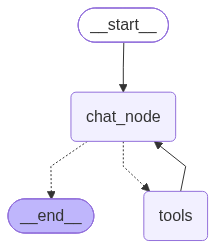

In [25]:
chatbot

In [26]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN"
                )
            )
        ]
    }
)

In [27]:
print(result['messages'][-1].content)


Below is a concise, step‑by‑step guide – taken directly from the **“Introduction to Machine Learning with Python”** notes – on how to pick the *ideal* number of neighbours \(K\) for a k‑Nearest‑Neighbors (k‑NN) model.

---

## 1. Why we need to tune \(K\)

| \(K\) | Effect on the model |
|------|--------------------|
| 1 | Very low bias, but high variance → the classifier can easily over‑fit noisy points. |
| large (e.g. ≥ 30) | High bias, low variance → the decision boundary becomes overly smooth and may under‑fit. |
| optimal \(K\) | A sweet‑spot where the model generalises best to unseen data. |

The notes (Chapter 2, “Supervised Learning”) stress that **k‑NN is very sensitive to the choice of \(K\)**, and that the usual way to locate the sweet‑spot is to **evaluate performance on data that were not used to train the model**.

---

## 2. The basic recipe (grid‑search + cross‑validation)

The book (Chapter 5, “Model Evaluation and Improvement”) describes the exact workflow we should 